# Did students vote twice? Checking the duplicate-voter claim — parliamentary election (19 Apr 2026)

**The claim:** many people who were *not* on a station's printed voter list, students in particular, voted more than once. For
example, a student voted in **Sofia in the morning** and again in **Plovdiv in the afternoon**.

## What the published data can and cannot show
The CIK open data are **counts per polling station**: no names, no ID numbers, no times of day. So no statistical test on them can
show that *a particular person* voted twice. That can only be checked by matching the **signed voter lists** against each other.
After every election ГРАО does exactly this, and the cases go to the prosecutor's office. That check, not this notebook, is the
definitive answer.

What the counts *can* do is test the **necessary footprint** of large-scale double voting:

1. **Where would a double voter show up?** A person is on exactly one printed list. To vote a second time somewhere else they must be
   **added on election day** (“под чертата”) at that second station, unless the voter lists themselves contain the person twice (a list
   error, which these data can't see). So large-scale double voting via the added-voter channel must produce **more added voters** in
   the places where it happened.
2. **Is there such a surplus?** Compare the number of added voters in Sofia and Plovdiv, and at the stations that serve students, with
   (a) the same stations in the **two presidential rounds** six months later, and (b) the rest of the country.
3. **Who would it have helped?** Look at how the stations that serve students voted.
4. **Could it matter?** Put an **upper bound** on the number of votes this channel could have produced and compare it with what it would
   take to change the majority (≈ 221,500 votes, see `ballot_anomalies_parliament.ipynb`, section 7).

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from load_data import load_votes, load_sections, PARLIAMENT, ROUND1, ROUND2

NONE = "Не подкрепям никого"
short = lambda c: c.split(" ", 1)[1] if c[:2].isdigit() else c

def prep(election):
    m = load_sections(election)
    m["district"] = m.index.str[:6]                    # region + municipality + city district (e.g. Sofia's 24 districts)
    m["registered"] = m["voters_list"] + m["voters_added"]
    m["voted"] = m["voted_signatures"]
    return m

P, R1, R2 = prep(PARLIAMENT), prep(ROUND1), prep(ROUND2)
votes = load_votes(election=PARLIAMENT)
cand_cols = [c for c in votes.columns if c != NONE]
ranked = list(votes[cand_cols].sum().sort_values(ascending=False).index)
WIN = ranked[0]
P = P.join(votes)
P["valid"] = votes.sum(axis=1)
MAJORITY_MARGIN = 221_555        # votes that would have to be removed from the winner to lose the majority (ballot_anomalies_parliament §7)
print(f"stations: parliament {len(P):,}, presidential round 1 {len(R1):,}, round 2 {len(R2):,}")

stations: parliament 12,721, presidential round 1 12,719, round 2 12,717


In [2]:
# ---- chart style ----
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#c3c2b7", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 10, "figure.dpi": 110,
    "legend.frameon": False,
})
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
def suptitle(fig, s): fig.suptitle(s, x=0.01, ha="left", fontsize=13, fontweight="bold")

## 1. How many voters were added on election day, and where?
Abroad, almost every voter is “added” (there are no pre-made lists), and nobody can vote abroad and in Bulgaria on the same day in any
number. So we look at **domestic** stations only. Areas: the three Sofia constituencies (23, 24, 25 МИР), the city of Plovdiv (16 МИР),
the rest of the Plovdiv region (17 МИР), and the rest of the country.

In [3]:
def area(m):
    r = m["region"]
    return np.select([r.isin([23, 24, 25]), r == 16, r == 17, r == 32], ["Sofia", "Plovdiv city", "Plovdiv region", "abroad"], "rest of Bulgaria")

rows = {}
for name, m in [("parliament (Apr)", P), ("presidential r1 (Oct)", R1), ("presidential r2 (Nov)", R2)]:
    g = m.assign(area=area(m)).groupby("area")[["voters_added", "voted"]].sum()
    for a_, r_ in g.iterrows():
        rows[(a_, name)] = {"voters added": r_["voters_added"], "voted": r_["voted"], "added per 100 voters": 100 * r_["voters_added"] / r_["voted"]}
by_area = pd.DataFrame(rows).T
by_area = by_area.loc[["Sofia", "Plovdiv city", "Plovdiv region", "rest of Bulgaria", "abroad"]]
by_area.style.format({"voters added": "{:,.0f}", "voted": "{:,.0f}", "added per 100 voters": "{:.2f}"})

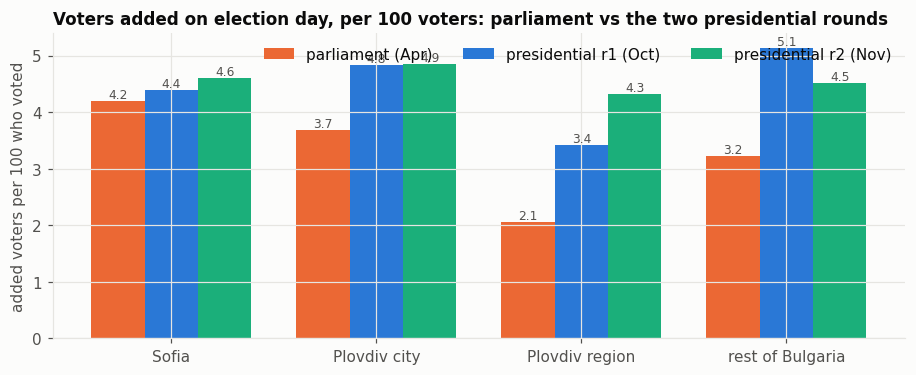

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.6))
areas = ["Sofia", "Plovdiv city", "Plovdiv region", "rest of Bulgaria"]
x = np.arange(len(areas)); wdt = 0.26
for i, (name, col) in enumerate([("parliament (Apr)", ORANGE), ("presidential r1 (Oct)", BLUE), ("presidential r2 (Nov)", AQUA)]):
    vals = [by_area.loc[(a_, name), "added per 100 voters"] for a_ in areas]
    ax.bar(x + (i - 1) * wdt, vals, width=wdt, color=col, label=name)
    for xi, v in zip(x + (i - 1) * wdt, vals): ax.text(xi, v + 0.05, f"{v:.1f}", ha="center", fontsize=8, color=INK2)
ax.set_xticks(x, areas); ax.set_ylabel("added voters per 100 who voted"); ax.legend(ncol=3, loc="upper right")
ax.set_title("Voters added on election day, per 100 voters: parliament vs the two presidential rounds")
plt.show()

**Reading it:** the parliamentary election had far more voters overall (turnout ~48% vs ~22–27%), so it also had more added voters in
absolute numbers. **Per voter, however, it had fewer added voters than both presidential rounds**, in Sofia, in Plovdiv and in the rest
of the country. Mass double voting through the added-voter channel would push the parliamentary bars *up*.

## 2. Who are the added voters? Station types
Added voters cluster in places where people are legitimately away from home on election day. We classify every domestic station by
its address: hospitals and sanatoria, care homes, prisons, **student areas** (Sofia's Студентски град, dormitories, universities), and
everything else.

In [5]:
PATTERNS = {
    "hospital / sanatorium": r"БАЛ|БОЛНИЦ|КЛИНИК|ДКЦ|СБР|ВМА|ДПБ|ПСИХИАТР|МЕДИЦИНСКИ ИНСТИТУТ|МАЙЧИН ДОМ|РЕХАБИЛИТ|ТОКУДА|ПЪЛМЕД|КАСПЕЛА|МЕДИКА",
    "care home / institution": r"ДОМ ЗА СТАРИ|ДСХ|ДОМ НА ИНВАЛИДА|ЦНСТ|СОЦИАЛН|ДОМ ЗА ВЪЗРАСТНИ|ХОСПИС",
    "prison": r"ЗАТВОР|АРЕСТ|ПОПРАВИТЕЛ",
    "student area": r"СТУДЕНТСКИ ГРАД|ОБЩЕЖИТ|УНИВЕРСИТЕТ|УНСС|АКАДЕМИЯ(?! ВМА)",
}
def station_type(addr):
    a_ = str(addr).upper()
    for k, pat in PATTERNS.items():
        if re.search(pat, a_): return k
    return "other"

for m in (P, R1, R2):
    m["type"] = m["address"].map(station_type)
    m["area"] = area(m)

dom = lambda m: m[m["area"] != "abroad"]
tt = {}
for name, m in [("parliament", P), ("pres. r1", R1), ("pres. r2", R2)]:
    g = dom(m).groupby(["area", "type"])[["voters_added", "voted"]].sum()
    tt[name] = g["voters_added"]
    tt[f"{name} per 100"] = 100 * g["voters_added"] / g["voted"]
types_tab = pd.DataFrame(tt).fillna(0)
types_tab = types_tab.loc[[a_ for a_ in ["Sofia", "Plovdiv city", "Plovdiv region", "rest of Bulgaria"]]]
types_tab.style.format({c: "{:,.0f}" for c in types_tab.columns if "per 100" not in c} | {c: "{:.1f}" for c in types_tab.columns if "per 100" in c})

In [6]:
st = P[(P["type"] == "student area") & (P["area"] != "abroad")]
print(f"{len(st)} domestic stations in student areas; by city:")
print(st.groupby("place").agg(stations=("voted", "size"), added=("voters_added", "sum"), voted=("voted", "sum")).sort_values("added", ascending=False).head(10).to_string())
print()
print("Plovdiv city: no station address mentions a dormitory, Студентски град or a university, except:",
      ", ".join(P.loc[(P["region"] == 16) & P["address"].str.upper().str.contains("ОБЩЕЖИТ|УНИВЕРСИТЕТ|СТУДЕНТ"), "address"].str[:60]) or "none")

52 domestic stations in student areas; by city:
                   stations  added  voted
place                                    
гр.София                 15   3409  11563
гр.Варна                 18    397   8019
гр.Стара Загора           3    175   1076
гр.Велико Търново         1    121    152
гр.Смолян                 3     23    861
гр.Габрово                2     21    560
гр.Видин                  1     12    288
гр.Шумен                  1      9    489
гр.Мадан                  1      8    222
гр.Пловдив                1      8    195

Plovdiv city: no station address mentions a dormitory, Студентски град or a university, except: ГР.ПЛОВДИВ, Общежитие на слепите - фоайе ул. Ландос №24


**Reading it:** in Sofia the student areas are a real cluster of added voters (Студентски град). In **Plovdiv there is no student cluster
at all**: its added voters are overwhelmingly in hospitals. If Sofia students had travelled to Plovdiv to vote a second time, they
would have had to be added at ordinary neighbourhood stations in Plovdiv, which section 3 tests directly.

## 3. Station by station: more added voters than the same station had in the presidential election?
For every domestic station that exists in all three elections we predict how many added voters it "should" have had in the parliamentary
election, from its **own added-voter rate in the two presidential rounds** (shrunk towards its municipality's rate when the station is small):

$$\text{expected}_{\text{parl}} = \text{voted}_{\text{parl}} \times \frac{\text{added}_{r1} + \text{added}_{r2} + 50\,\bar r_{\text{municipality}}}{\text{voted}_{r1} + \text{voted}_{r2} + 50}$$

We then test each station for **too many** added voters (Poisson, Benjamini–Hochberg q < 0.01), and add up the **excess** (observed −
expected) by area. A station whose list changed by more than 30% between the elections is dropped (a re-drawn station is not comparable).

In [7]:
common = P.index.intersection(R1.index).intersection(R2.index)
S = pd.DataFrame(index=common)
for col in ["area", "type", "place", "address", "municipality", "district", "region", "voters_list", "voters_added", "voted", "valid"] + cand_cols:
    S[col] = P.loc[common, col]
for tag, m in [("r1", R1), ("r2", R2)]:
    S[f"added_{tag}"], S[f"voted_{tag}"], S[f"list_{tag}"] = m.loc[common, "voters_added"], m.loc[common, "voted"], m.loc[common, "voters_list"]
S = S[(S["area"] != "abroad") & (S["voted"] > 0) & (S["voted_r1"] + S["voted_r2"] > 0)]
S = S[(S["voters_list"] / S["list_r1"].clip(lower=1) - 1).abs() < 0.3]
muni_rate = (S.groupby("municipality")[["added_r1", "added_r2"]].sum().sum(axis=1)
             / S.groupby("municipality")[["voted_r1", "voted_r2"]].sum().sum(axis=1))
S["muni_rate"] = S["municipality"].map(muni_rate)
S["pres_rate"] = (S["added_r1"] + S["added_r2"] + 50 * S["muni_rate"]) / (S["voted_r1"] + S["voted_r2"] + 50)
S["expected"] = S["voted"] * S["pres_rate"]
S["excess"] = S["voters_added"] - S["expected"]
S["p"] = stats.poisson.sf(S["voters_added"] - 1, S["expected"].clip(lower=0.5))
S["q"] = stats.false_discovery_control(S["p"])
S["flag"] = (S["q"] < 0.01) & (S["excess"] >= 10)
print(f"{len(S):,} domestic stations comparable across all three elections")
summary = S.groupby("area").agg(stations=("voted", "size"), added_parl=("voters_added", "sum"), expected=("expected", "sum"),
                                flagged=("flag", "sum"), excess_in_flagged=("excess", lambda e: e[S.loc[e.index, "flag"]].sum()))
summary["observed ÷ expected"] = summary["added_parl"] / summary["expected"]
summary.loc["total"] = summary.sum(numeric_only=True)
summary.loc["total", "observed ÷ expected"] = summary.loc["total", "added_parl"] / summary.loc["total", "expected"]
summary.style.format({"added_parl": "{:,.0f}", "expected": "{:,.0f}", "excess_in_flagged": "{:,.0f}", "observed ÷ expected": "{:.2f}",
                      "stations": "{:,.0f}", "flagged": "{:.0f}"})

11,065 domestic stations comparable across all three elections


,stations,added_parl,expected,flagged,excess_in_flagged,observed ÷ expected
area,,,,,,
Plovdiv city,455,"4,723","6,526",1,19,0.72
Plovdiv region,496,"2,458","4,794",1,24,0.51
Sofia,"1,579","22,333","23,203",10,"1,807",0.96
rest of Bulgaria,"8,535","60,913","92,138",20,"2,988",0.66
total,"11,065","90,427","126,661",32,"4,838",0.71


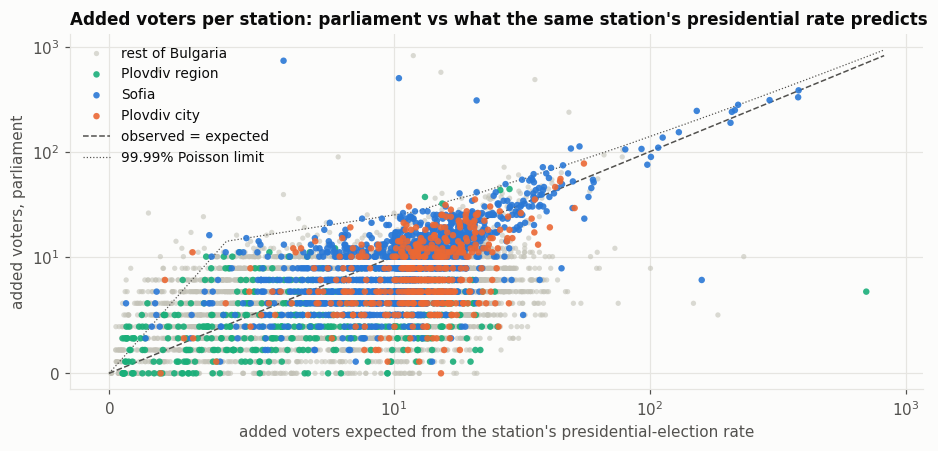

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for a_, col in [("rest of Bulgaria", MUTED), ("Plovdiv region", AQUA), ("Sofia", BLUE), ("Plovdiv city", ORANGE)]:
    t = S[S["area"] == a_]
    ax.scatter(t["expected"], t["voters_added"], s=12 if a_ == "rest of Bulgaria" else 18, color=col, alpha=0.6 if a_ == "rest of Bulgaria" else 0.9,
               label=a_, edgecolor="none", zorder=2 if a_ == "rest of Bulgaria" else 3)
mx = max(S["expected"].max(), S["voters_added"].max())
xx = np.linspace(0, mx, 200)
ax.plot(xx, xx, color=INK2, lw=1, ls="--", label="observed = expected")
ax.plot(xx, stats.poisson.ppf(0.9999, xx), color=INK2, lw=0.8, ls=":", label="99.99% Poisson limit")
ax.set_xscale("symlog", linthresh=10); ax.set_yscale("symlog", linthresh=10)
ax.set_xlabel("added voters expected from the station's presidential-election rate"); ax.set_ylabel("added voters, parliament")
ax.legend(loc="upper left", fontsize=9); ax.set_title("Added voters per station: parliament vs what the same station's presidential rate predicts")
plt.show()

In [9]:
cols = ["area", "type", "place", "address", "voters_list", "voters_added", "expected", "added_r1", "voted_r1", "added_r2", "voted_r2", "voted", "q"]
S["top party"] = S[cand_cols].idxmax(axis=1).map(short)
S["top share"] = S[cand_cols].max(axis=1) / S["valid"]
F = S[S["flag"]].sort_values("excess", ascending=False)
print(f"{len(F)} stations with significantly more added voters than in the presidential election; total excess {F['excess'].sum():,.0f}")
print(F.groupby(["area", "type"]).agg(stations=("excess", "size"), excess=("excess", "sum")).round(0).to_string())
F[cols + ["top party", "top share"]].head(30).style.format({"expected": "{:.0f}", "q": "{:.0e}", "top share": "{:.0%}",
                                                            "added_r1": "{:.0f}", "voted_r1": "{:.0f}", "added_r2": "{:.0f}", "voted_r2": "{:.0f}"})

32 stations with significantly more added voters than in the presidential election; total excess 4,838
                                        stations  excess
area             type                                   
Plovdiv city     other                         1    19.0
Plovdiv region   hospital / sanatorium         1    24.0
Sofia            hospital / sanatorium         1   286.0
                 other                         9  1521.0
rest of Bulgaria hospital / sanatorium         3   225.0
                 other                        15  2690.0
                 student area                  2    73.0


,area,type,place,address,voters_list,voters_added,expected,added_r1,voted_r1,added_r2,voted_r2,voted,q,top party,top share
section,,,,,,,,,,,,,,,
030604324,rest of Bulgaria,other,гр.Варна,"ГР.ВАРНА, ОУ Стоян Михайловски , ж.к. Вл. Варненчик II м.р.",815,820,12,6,176,6,210,378,0e+00,Прогресивна България,56%
254620031,Sofia,other,гр.София,"ГР.СОФИЯ, Връбница 1, 74 СОУ Гоце Делчев ет. 2, крило Г",733,733,6,3,245,4,297,414,0e+00,Прогресивна България,42%
062000023,rest of Bulgaria,other,с.Бутан,"С.БУТАН, СУ Св. Св. Кирил и Методий ул. Христо Ботев №1",596,597,2,0,40,0,56,214,0e+00,Прогресивна България,45%
010300012,rest of Bulgaria,other,гр.Благоевград,"ГР.БЛАГОЕВГРАД, V-то СУ ГЕОРГИ ИЗМИРЛИЕВ , УЛ. ХРИСТО ЧЕРНОПЕЕВ №16",569,569,15,7,131,8,171,309,0e+00,Прогресивна България,47%
254618068,Sofia,other,гр.София,"ГР.СОФИЯ, 149 СУ Иван Хаджийски ж.к. Овча купел-2",521,500,10,7,194,6,217,327,0e+00,Прогресивна България,41%
040400008,rest of Bulgaria,other,гр.Велико Търново,"ГР.ВЕЛИКО ТЪРНОВО, ВТУ V-ти корпус (двора на бивше Военно училище), пл. Център №1",484,485,36,26,158,19,177,290,0e+00,Прогресивна България,40%
234609081,Sofia,hospital / sanatorium,гр.София,„АДЖИБАДЕМ СИТИ КЛИНИК УМБАЛ ТОКУДА“ ЕАД /бул. „Никола Вапцаров“ № 51-Б,553,307,21,14,246,18,291,363,3e-232,Прогресивна България,36%
030602403,rest of Bulgaria,hospital / sanatorium,гр.Варна,"ГР.ВАРНА, УМБАЛ Св.Марина , ул. Христо Смирненски №1",74,237,48,12,56,12,54,300,7e-81,Прогресивна България,46%
234616050,Sofia,other,гр.София,"ГР.СОФИЯ, ПГ по телекомуникации, ул. Акад. Стефан Младенов №1",811,244,152,85,417,82,448,824,3e-09,Прогресивна България,35%


**A recurring protocol error.** Several of the top stations have **almost exactly as many “added” voters as voters on the list**
(e.g. 815 on the list, 820 added, 378 voted). That is impossible as real behaviour: everyone added on the day is added in order to vote,
so the number added can never exceed the number who voted. The committee evidently copied the list size into the “added” field. The same kind of slip appeared in the presidential
notebooks (the list size copied from the number who voted). These stations inflate the added-voter totals without a single extra
person voting.

In [10]:
# every added voter is added in order to vote, so 'added' can never exceed 'voted'
copy_err = (S["voters_added"] >= 20) & (S["voters_added"] > S["voted"])
copy_err_all = (P["area"] != "abroad") & (P["voters_added"] >= 20) & (P["voters_added"] > P["voted"])
CE = P.loc[copy_err_all, ["place", "address", "voters_list", "voters_added", "voted", "type"]]
print(f"stations with more 'added' voters than voters in total (copy error): {copy_err_all.sum()} (of which {copy_err.sum()} among the comparable stations); "
      f"they account for {CE['voters_added'].sum():,} 'added voters'")
print(f"excess in flagged stations: {F['excess'].sum():,.0f} in total, {F.loc[F.index.isin(CE.index), 'excess'].sum():,.0f} of it in copy-error stations")
print(f"→ flagged excess without the copy errors: {F.loc[~F.index.isin(CE.index), 'excess'].sum():,.0f} added voters in "
      f"{(~F.index.isin(CE.index)).sum()} stations")
CE.sort_values("voters_added", ascending=False)

stations with more 'added' voters than voters in total (copy error): 10 (of which 8 among the comparable stations); they account for 4,784 'added voters'
excess in flagged stations: 4,838 in total, 3,737 of it in copy-error stations
→ flagged excess without the copy errors: 1,101 added voters in 24 stations


,place,address,voters_list,voters_added,voted,type
section,,,,,,
030604324,гр.Варна,"ГР.ВАРНА, ОУ Стоян Михайловски , ж.к. Вл. Вар...",815,820,378,other
254620031,гр.София,"ГР.СОФИЯ, Връбница 1, 74 СОУ Гоце Делчев ет....",733,733,414,other
030601029,гр.Варна,"ГР.ВАРНА, СУ Димчо Дебелянов , ул. Русе №2",401,706,399,other
062000023,с.Бутан,"С.БУТАН, СУ Св. Св. Кирил и Методий ул. Хри...",596,597,214,other
010300012,гр.Благоевград,"ГР.БЛАГОЕВГРАД, V-то СУ ГЕОРГИ ИЗМИРЛИЕВ , УЛ....",569,569,309,other
254618068,гр.София,"ГР.СОФИЯ, 149 СУ Иван Хаджийски ж.к. Овча ку...",521,500,327,other
040400008,гр.Велико Търново,"ГР.ВЕЛИКО ТЪРНОВО, ВТУ V-ти корпус (двора на б...",484,485,290,other
091600113,с.Звезделина,"С.ЗВЕЗДЕЛИНА, детската градина",614,246,245,other
221600029,с.Вехтино,"С.ВЕХТИНО, Кметство Вехтино",89,89,55,other


**Reading it:** of 11,065 comparable stations, only **24 genuinely have more added voters than in the presidential election**
(after removing the copy errors), with a combined excess of **~1,100 voters**. They are the Токуда and Св. Марина hospitals, and stations in
**university towns and districts**: Sofia's Студентски район (ПГ по телекомуникации, 55 СУ), Благоевград, Велико Търново, Варна's
Икономически университет. That fits students voting where they study, which they did a little more in a high-stakes election.
Per station it is tens of voters, not hundreds.

Every area as a whole had **fewer** added voters than its presidential rate predicts (observed ÷ expected 0.51–0.96). Most "added voters"
are people who are routinely added, such as hospital patients, and their number doesn't grow with turnout.

## 4. The Sofia → Plovdiv scenario specifically
The specific story is: a student who is **on a list in one city** votes there normally, and is **added** at a station in the other city to
vote a second time. Either way round (Sofia morning / Plovdiv afternoon or the reverse), one of the two cities has to absorb the
**added** votes. Three checks:
* **Plovdiv:** did Plovdiv's stations, in any district, have more added voters than their own presidential-election rate predicts?
* **Sofia student areas:** did Студентски град and the other student-area stations have more added voters than in the presidential election?
* **Same profile?** If the same group voted in both cities, the extra added voters in Plovdiv should vote like Sofia's student areas.

In [11]:
focus = S[S["area"].isin(["Sofia", "Plovdiv city"])].copy()
focus["group"] = np.where(focus["area"] == "Plovdiv city", "Plovdiv: " + focus["district"].map({
    "162201": "Централен", "162202": "Източен", "162203": "Западен", "162204": "Северен", "162205": "Южен", "162206": "Тракия"}).fillna(focus["district"]),
    np.where(focus["type"] == "student area", "Sofia: student areas", "Sofia: other"))
g = focus.groupby("group").agg(stations=("voted", "size"), voted=("voted", "sum"), added=("voters_added", "sum"), expected=("expected", "sum"),
                               added_r1=("added_r1", "sum"), voted_r1=("voted_r1", "sum"), added_r2=("added_r2", "sum"), voted_r2=("voted_r2", "sum"))
g["excess"] = g["added"] - g["expected"]
g["per 100 voters: parl."] = 100 * g["added"] / g["voted"]
g["per 100: pres. r1"] = 100 * g["added_r1"] / g["voted_r1"]
g["per 100: pres. r2"] = 100 * g["added_r2"] / g["voted_r2"]
# uncertainty of the excess: Poisson noise of the observed count
g["excess 95% range"] = [f"{e - 1.96 * np.sqrt(o):+,.0f} … {e + 1.96 * np.sqrt(o):+,.0f}" for e, o in zip(g["excess"], g["added"])]
g[["stations", "added", "expected", "excess", "excess 95% range", "per 100 voters: parl.", "per 100: pres. r1", "per 100: pres. r2"]].style.format(
    {"added": "{:,.0f}", "expected": "{:,.0f}", "excess": "{:+,.0f}", "per 100 voters: parl.": "{:.1f}", "per 100: pres. r1": "{:.1f}", "per 100: pres. r2": "{:.1f}"})

,stations,added,expected,excess,excess 95% range,per 100 voters: parl.,per 100: pres. r1,per 100: pres. r2
group,,,,,,,,
Plovdiv: Западен,43,493,676,-183,-227 … -140,2.9,4.2,4.5
Plovdiv: Източен,71,607,975,-368,-416 … -320,4.3,7.1,7.4
Plovdiv: Северен,73,820,"1,051",-231,-287 … -174,3.6,4.6,4.8
Plovdiv: Тракия,76,587,894,-307,-354 … -259,2.2,3.3,3.4
Plovdiv: Централен,100,"1,272","1,492",-220,-290 … -150,3.6,4.2,4.1
Plovdiv: Южен,92,944,"1,438",-494,-554 … -434,2.6,4.0,4.0
Sofia: other,1571,"20,553","21,510",-957,"-1,238 … -676",3.4,3.5,3.6
Sofia: student areas,8,"1,780","1,693",+87,+5 … +170,30.3,28.1,31.1


In [12]:
# How did the student areas vote, compared with Sofia and Plovdiv overall?
def shares(t): return t[cand_cols].sum() / t["valid"].sum()
prof = pd.DataFrame({
    "Sofia student areas": shares(P[(P["area"] == "Sofia") & (P["type"] == "student area")]),
    "Sofia overall": shares(P[P["area"] == "Sofia"]),
    "Plovdiv city overall": shares(P[P["area"] == "Plovdiv city"]),
    "Plovdiv stations flagged in §3": shares(S[S["flag"] & (S["area"] == "Plovdiv city")]) if (S["flag"] & (S["area"] == "Plovdiv city")).any() else np.nan,
    "whole country": shares(P),
})
prof.index = [short(c) for c in prof.index]
prof.loc[[short(c) for c in ranked[:6]]].style.format("{:.1%}")

,Sofia student areas,Sofia overall,Plovdiv city overall,Plovdiv stations flagged in §3,whole country
Прогресивна България,33.3%,35.3%,45.4%,32.9%,43.9%
ГЕРБ–СДС,6.3%,13.0%,12.9%,11.9%,13.2%
ПП–ДБ,38.5%,25.5%,16.1%,28.1%,12.4%
ДПС,0.5%,0.8%,1.0%,1.0%,7.0%
Възраждане,3.1%,4.7%,4.6%,6.2%,4.2%
МЕЧ,3.7%,3.2%,3.5%,2.9%,3.2%


**Reading it:**
* **Plovdiv:** every one of Plovdiv's six districts had **fewer** added voters than its own presidential rate predicts, by 180–490 per
  district (about −1,800 in total, far outside the noise). Nowhere in Plovdiv is there a surplus that could hold hundreds of Sofia students.
* **Sofia student areas:** **+87 added voters** over the presidential rate (95% range +5 to +170), across 8 comparable stations. Студентски
  град had many added voters, but no more than it always has (30 per 100 voters, against 28 and 31 in the two presidential rounds).
* **Profile:** Sofia's student areas voted **ПП–ДБ 38.5%, Прогресивна България 33.3%**, *below* the winner's 35% in Sofia and 44% nationally.
  The one Plovdiv station with a significant surplus (+19 voters) has no student profile.

For the "Sofia in the morning, Plovdiv in the afternoon" story to be true at any meaningful scale, Plovdiv would need hundreds to thousands
of extra added voters. It has about 1,800 *fewer* than usual.

## 5. Upper bound: how many votes could this channel have produced at most?
Even without knowing who the added voters were, we can bound what double voting *through added voters* could have done to the result,
from the most pessimistic assumptions down to the most realistic:

In [13]:
dom_P = P[P["area"] != "abroad"]
bounds = pd.Series({
    "every domestic added voter was a double voter (absurd worst case)": dom_P["voters_added"].sum(),
    "… excluding hospitals, care homes and prisons": dom_P.loc[~dom_P["type"].isin(["hospital / sanatorium", "care home / institution", "prison"]), "voters_added"].sum(),
    "every added voter in Sofia + Plovdiv city": dom_P.loc[dom_P["area"].isin(["Sofia", "Plovdiv city"]), "voters_added"].sum(),
    "every added voter in Sofia student areas": dom_P.loc[(dom_P["area"] == "Sofia") & (dom_P["type"] == "student area"), "voters_added"].sum(),
    "excess over the presidential rate, all stations (§3)": S["excess"].clip(lower=0).sum(),
    "excess in significantly flagged stations only (§3)": F["excess"].sum(),
    "… without the 'added > voted' copy errors": F.loc[~F.index.isin(CE.index), "excess"].sum(),
}, name="votes")
bt = bounds.to_frame()
bt["share of the votes needed to lose the majority"] = bt["votes"] / MAJORITY_MARGIN
bt["if ALL went to " + short(WIN) + " and were removed: seats left"] = None
from load_data import load_votes as _lv
party_tot = votes[cand_cols].sum(); valid_all = votes.sum().sum()
def hare_niemeyer(v, seats=240, threshold=0.04, base=None):
    base = v.sum() if base is None else base
    ok = v[v >= threshold * base]; q = ok / ok.sum() * seats; s_ = np.floor(q).astype(int)
    s_[(q - s_).sort_values(ascending=False).index[: seats - s_.sum()]] += 1
    return s_
for k, n in bounds.items():
    v_ = party_tot.astype(float).copy(); v_[WIN] -= n
    bt.loc[k, "if ALL went to " + short(WIN) + " and were removed: seats left"] = hare_niemeyer(v_, base=valid_all - n)[WIN]
bt.style.format({"votes": "{:,.0f}", "share of the votes needed to lose the majority": "{:.0%}"})

,votes,share of the votes needed to lose the majority,if ALL went to Прогресивна България and were removed: seats left
every domestic added voter was a double voter (absurd worst case),"107,457",49%,126
"… excluding hospitals, care homes and prisons","96,754",44%,126
every added voter in Sofia + Plovdiv city,"32,599",15%,129
every added voter in Sofia student areas,"3,409",2%,130
"excess over the presidential rate, all stations (§3)","12,239",6%,130
excess in significantly flagged stations only (§3),"4,838",2%,130
… without the 'added > voted' copy errors,"1,101",0%,131


Note that the "absurd worst case" also assumes every one of these voters chose the winner. In reality the added voters at Sofia's student
stations voted **less** for Прогресивна България than Sofia as a whole (section 4), so if anything the student vote cut against the winner.

## 6. What this does *not* rule out
* **Duplicate entries in the printed lists.** If a person is on the permanent-address list in one city *and* (by mistake) on a
  current-address list in another, they can vote twice without ever being "added". These data can't see that. ГРАО's post-election
  matching of signed lists does.
* **Small-scale double voting.** Dozens or a few hundred cases spread over many stations disappear in normal variation. They would be
  illegal and should be prosecuted, but they cannot move a majority that needs ~221,500 votes.
* **Times of day.** The open data contain no voting times. CIK publishes turnout per region at fixed hours on election day, but not per
  station and not per person, so the "morning in Sofia, afternoon in Plovdiv" timeline cannot be reconstructed from public data.

## 7. Conclusions

| Question | Finding |
|---|---|
| Did the parliamentary election have unusually many voters added on the day? | **No.** Per voter it had *fewer* than both presidential rounds: Sofia 4.2 vs 4.4–4.6 per 100, Plovdiv 3.7 vs 4.8–4.9, rest of the country 3.2 vs 4.5–5.1. |
| Where are the added voters? | Hospitals, sanatoria, prisons, and in Sofia the student town (Студентски град). **Plovdiv has no student cluster**; its added voters are in hospitals. |
| More added voters than the same station had in the presidential election? | Only 24 stations (excess ~1,100), mostly hospitals and university-town stations. Every area as a whole had fewer added voters than predicted. |
| Sofia → Plovdiv specifically? | Plovdiv: ~1,800 **fewer** added voters than its presidential rate predicts, in every district. Sofia student areas: +87 (range +5 … +170). |
| Who would student votes have helped? | Sofia's student areas voted **ПП–ДБ first (38.5%)**; Прогресивна България got 33%, below its Sofia and national result. |
| Could double voting via added voters have created the majority? | **No.** Even if *every* domestic added voter (107,457) had been a double voter voting for the winner, it would keep **126 seats**. Removing every added voter in Sofia + Plovdiv (32,599) would leave it with 129. The realistic excess is ~1,100. |
| Data errors found | 10 stations report more "added" voters than people who voted (the list size copied into the field), inflating the added count by ~4,800. |

### Bottom line
**The published data contain no trace of large-scale double voting by students or anyone else through the added-voter channel**, and the
channel is too small to have created the majority even in an absurd worst case. In particular there is no surplus of added voters in
Plovdiv, so the "Sofia in the morning, Plovdiv in the afternoon" story finds no support in the counts. The student areas that do exist voted
*less* for the winner than the rest of the country.

What this cannot exclude is **individual or small-scale double voting** (tens or hundreds of cases), and double voting through **duplicate
entries in the printed lists**. Both are crimes that only a match of the signed voter lists can establish. ГРАО's post-election check of
the voter lists, and any resulting prosecutor's files, are the place to look for named cases. If those turn up only dozens or hundreds of
cases, they fit everything here. If they turned up tens of thousands, the counts above would be hard to reconcile with them.